## 探索性数据分析实验

##### 数据说明：`Highway1.csv`
The data comes from an unpublished master's paper by Carl Hoffstedt. They relate the automobile accident rate, in accidents per million vehicle miles to several potential terms. The data include 39 sections of large highways in the state of Minnesota in 1973. The goal of this analysis was to understand the impact of design variables, `acpts`, `slim`, `sig`, and `shld` that are under the control of the highway department, on accidents.

- **rate**: 1973 accident rate per million miles 每百万英里的事故发生率
- **len**: length of the Highway1 segment in miles 公路长度
- **adt**: average daily traffic count in thousands 日均车流量
- **trks**: truck volume as a percent of the total volume 卡车占比
- **sigs1**: (number of signalized interchanges per mile times len + 1)/len, the number of signals per mile of roadway, adjusted to have no zero values 每英里交通信号灯数量
- **slim**: speed limit in 1973 限速
- **shld**: width in feet of outer shoulder on the roadway 道路外侧路肩的宽度
- **lane**: total number of lanes of traffic 车道数
- **acpt**: number of access points per mile 每英里汇入点数量
- **itg**: number of freeway-type interchanges per mile 每英里高速公路互通式立交的数量
- **lwid**: lane width, in feet 车道宽度
- **htype**: An indicator of the type of roadway or the source of funding for the road, either MC, FAI, PA, or MA 道路类型

*Reference*: <u>https://vincentarelbundock.github.io/Rdatasets/doc/carData/Highway1.html

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

In [3]:
df = pd.read_csv('Highway1.csv',index_col = 0)
df.head()

,rate,len,adt,trks,sigs1,slim,shld,lane,acpt,itg,lwid,htype
rownames,,,,,,,,,,,,
1,4.58,4.99,69,8,0.200401,55,10,8,4.6,1.20,12,FAI
2,2.86,16.11,73,8,0.062073,60,10,4,4.4,1.43,12,FAI
3,3.02,9.75,49,10,0.102564,60,10,4,4.7,1.54,12,FAI
4,2.29,10.65,61,13,0.093897,65,10,6,3.8,0.94,12,FAI
5,1.61,20.01,28,12,0.049975,70,10,4,2.2,0.65,12,FAI


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39 entries, 1 to 39
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   rate    39 non-null     float64
 1   len     39 non-null     float64
 2   adt     39 non-null     int64  
 3   trks    39 non-null     int64  
 4   sigs1   39 non-null     float64
 5   slim    39 non-null     int64  
 6   shld    39 non-null     int64  
 7   lane    39 non-null     int64  
 8   acpt    39 non-null     float64
 9   itg     39 non-null     float64
 10  lwid    39 non-null     int64  
 11  htype   39 non-null     object 
dtypes: float64(5), int64(6), object(1)
memory usage: 4.0+ KB


In [5]:
# 查看数值变量的基本描述性统计
df.describe()

,rate,len,adt,trks,sigs1,slim,shld,lane,acpt,itg,lwid
count,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.00000,39.000000
mean,3.933333,12.884103,19.615385,9.333333,0.510724,55.000000,6.871795,3.128205,12.158974,0.29641,11.948718
std,1.986044,7.609683,18.611846,2.354540,0.664696,5.848977,3.036441,1.360717,9.318338,0.41117,0.455881
min,1.610000,2.960000,1.000000,6.000000,0.045455,40.000000,1.000000,2.000000,2.200000,0.00000,10.000000
25%,2.630000,7.995000,5.000000,8.000000,0.087382,50.000000,4.000000,2.000000,6.950000,0.00000,12.000000
50%,3.050000,11.390000,13.000000,9.000000,0.176655,55.000000,8.000000,2.000000,10.300000,0.13000,12.000000
75%,4.595000,17.800000,24.000000,11.000000,0.715146,60.000000,10.000000,4.000000,14.600000,0.36000,12.000000
max,9.230000,40.090000,73.000000,15.000000,2.789330,70.000000,10.000000,8.000000,53.000000,1.54000,13.000000


In [6]:
# 查看分类变量的可能取值
df['htype'].unique()

array(['FAI', 'PA', 'MA', 'MC'], dtype=object)

### 探索最关心的变量：事故发生率

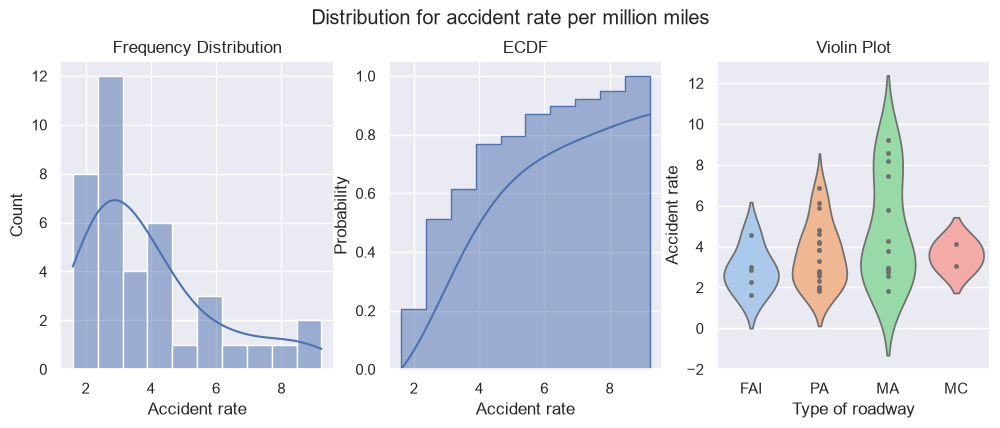

In [7]:
# 绘制事故发生率(rate)的密度分布
sns.set_theme()
sns.set_context(font_scale=2)
plt.figure(figsize=(12,4))
ax1 = plt.subplot(131)
ax1.set_title('Frequency Distribution') 
sns.histplot(data = df, x ='rate', bins=10, kde=True, ax=ax1) # 频数分布
plt.xlabel('Accident rate')

ax2 = plt.subplot(132)
ax2.set_title('ECDF')
sns.histplot(data = df, x ='rate', bins=10, kde=True, cumulative=True, element='step', stat='probability', ax=ax2) # 经验累积密度函数
plt.xlabel('Accident rate')

ax3 = plt.subplot(133)
ax3.set_title('Violin Plot')
sns.violinplot(data = df, x= 'htype', y = 'rate', hue='htype', palette='pastel', inner='point',ax = ax3) # 分类小提琴图
plt.xlabel('Type of roadway')
plt.ylabel('Accident rate')

plt.suptitle('Distribution for accident rate per million miles',y=1.01)
plt.show()

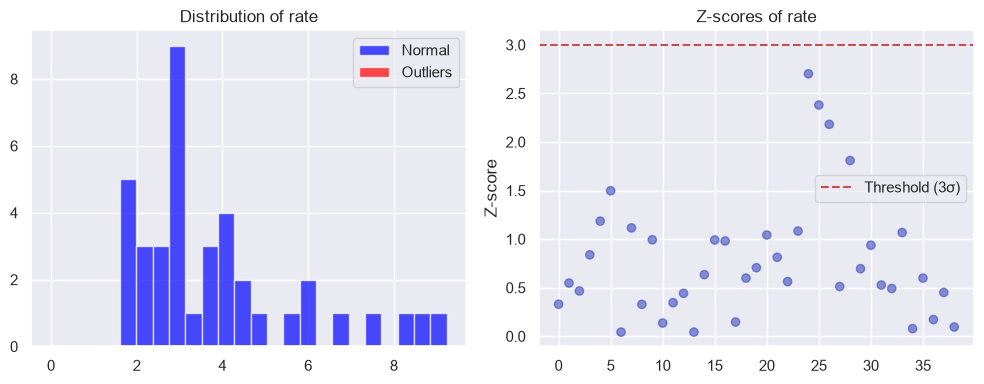

检测到 0 个异常值


In [8]:
# 事故发生率(rate)异常值检测

from scipy import stats
def zscore_outlier_plot(data, column, threshold=3):
    """基于Z-score的异常值可视化"""
    z_scores = np.abs(stats.zscore(data[column])) # 计算Z-score
    outliers = z_scores > threshold
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    
    # 原始数据分布
    axes[0].hist(data[column], bins=20, alpha=0.7, color='blue', label='Normal')
    axes[0].hist(data[column][outliers], bins=20, alpha=0.7, color='red', label='Outliers')
    axes[0].set_title(f'Distribution of {column}')
    axes[0].legend()
    
    # Z-score可视化
    axes[1].scatter(range(len(z_scores)), z_scores, alpha=0.6, 
                   c=outliers, cmap='coolwarm')
    axes[1].axhline(y=threshold, color='r', linestyle='--', label=f'Threshold ({threshold}σ)')
    axes[1].set_title(f'Z-scores of {column}')
    axes[1].set_ylabel('Z-score')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()
    
    print(f"检测到 {outliers.sum()} 个异常值")
    return outliers

# 调用函数
outliers = zscore_outlier_plot(df, 'rate')

### 变量相关系数矩阵
* 将类别变量进行独热编码
* 用编码后的变量替换原变量
* 使用pandas.Dataframe.corr计算相关系数矩阵

In [9]:
df_dummy = pd.get_dummies(df.htype) # 类别变量编码
df.drop(columns=['htype'],inplace=True)
df = pd.concat([df, df_dummy], axis = 1)
corr_matrix = df.corr() # 计算Pearson Correlation

In [10]:
df.head()

,rate,len,adt,trks,sigs1,slim,shld,lane,acpt,itg,lwid,FAI,MA,MC,PA
rownames,,,,,,,,,,,,,,,
1,4.58,4.99,69,8,0.200401,55,10,8,4.6,1.20,12,True,False,False,False
2,2.86,16.11,73,8,0.062073,60,10,4,4.4,1.43,12,True,False,False,False
3,3.02,9.75,49,10,0.102564,60,10,4,4.7,1.54,12,True,False,False,False
4,2.29,10.65,61,13,0.093897,65,10,6,3.8,0.94,12,True,False,False,False
5,1.61,20.01,28,12,0.049975,70,10,4,2.2,0.65,12,True,False,False,False


In [11]:
# 相关系数矩阵
corr_matrix

,rate,len,adt,trks,sigs1,slim,shld,lane,acpt,itg,lwid,FAI,MA,MC,PA
rate,1.000000,-0.465290,-0.028570,-0.512522,0.603191,-0.680984,-0.386907,-0.032979,0.752025,-0.024841,-0.005619,-0.207610,0.337848,-0.041311,-0.161540
len,-0.465290,1.000000,-0.271569,0.495943,-0.391851,0.186243,-0.104926,-0.202504,-0.238706,-0.247562,-0.310650,-0.029718,0.129595,0.111455,-0.151530
adt,-0.028570,-0.271569,1.000000,-0.096682,0.159381,0.244157,0.457307,0.823930,-0.223980,0.903701,0.127878,0.759477,-0.464828,-0.222924,0.028782
trks,-0.512522,0.495943,-0.096682,1.000000,-0.475308,0.296184,0.006135,-0.153324,-0.360266,-0.067231,-0.155271,0.142999,-0.101414,0.116707,-0.051501
sigs1,0.603191,-0.391851,0.159381,-0.475308,1.000000,-0.424415,-0.124103,0.263967,0.513461,0.087017,0.062084,-0.239015,-0.071937,-0.158419,0.297620
slim,-0.680984,0.186243,0.244157,0.296184,-0.424415,1.000000,0.689009,0.264520,-0.681521,0.241282,0.098693,0.464948,-0.423950,0.100673,0.044426
shld,-0.386907,-0.104926,0.457307,0.006135,-0.124103,0.689009,1.000000,0.481771,-0.424951,0.375022,-0.042896,0.400236,-0.623065,-0.106409,0.366881
lane,-0.032979,-0.202504,0.823930,-0.153324,0.263967,0.264520,0.481771,1.000000,-0.208779,0.697913,0.095723,0.591514,-0.512952,-0.195288,0.174316
acpt,0.752025,-0.238706,-0.223980,-0.360266,0.513461,-0.681521,-0.424951,-0.208779,1.000000,-0.200158,-0.042013,-0.342661,0.513488,-0.062154,-0.227661
itg,-0.024841,-0.247562,0.903701,-0.067231,0.087017,0.241282,0.375022,0.697913,-0.200158,1.000000,0.102883,0.808408,-0.355593,-0.169796,-0.130413


#### 热力图：`sns.heatmap()`

<Axes: >

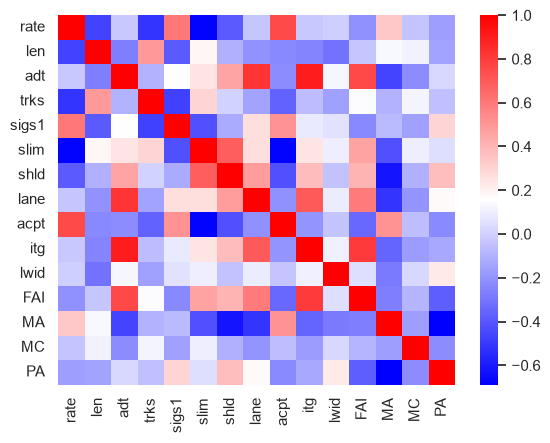

In [12]:
sns.heatmap(corr_matrix,cmap='bwr') # cmap: Spectral, bwr, PiYG, PRGn, coolwarm

In [13]:
# 设置mask以隐藏上三角区域
mask = np.zeros_like(corr_matrix, dtype=np.bool_) # 所有元素都为False的矩阵
mask[np.triu_indices_from(mask)]= True # 将矩阵上三角元素改为True, numpy.triu_indices_from()返回矩阵的上三角索引
mask

array([[ True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [False,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [False, False,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [False, False, False,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [False, False, False, False,  True,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [False, False, False, False, False,  True,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [False, False, False, False, False, False,  True,  True,  True,
         True,  True,  True,  True,  True,  True],
       [False, False, False, False, False, False, False,  True,  True,
         True,  True,  True,  True,  True,  True],
       [False, False, Fa

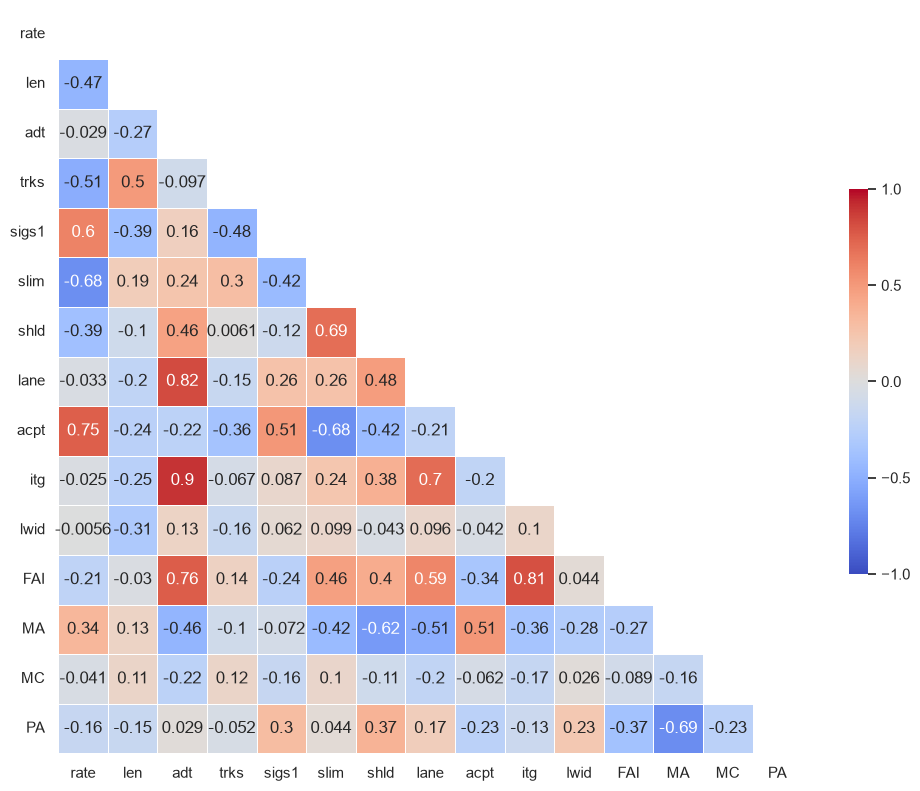

In [14]:
sns.set_style('white')
fig, ax = plt.subplots(figsize=(12, 10)) 
heatmap = sns.heatmap(corr_matrix, 
                      mask = mask, # 设置为定义好的mask
                      square = True,
                      linewidths = .5,
                      cmap ='coolwarm',
                      cbar_kws={"shrink": .5, 'ticks' : [-1, -.5, 0, 0.5, 1]},
                      vmin = -1, 
                      vmax = 1,
                      annot = True,
                      annot_kws = {"size": 12})

ax.set_yticklabels(corr_matrix.columns, rotation = 0)
plt.show()

In [15]:
# 图像导出
heatmap.get_figure().savefig('heatmap.png', bbox_inches='tight')

### 探索几个设计变量（可以人为调控的决策变量）

In [16]:
design_vars = ['acpt', 'slim', 'sigs1', 'shld']
labels = ['Num. of Access Points','Speed Limit','Num. of Signals','Shoulder Width']

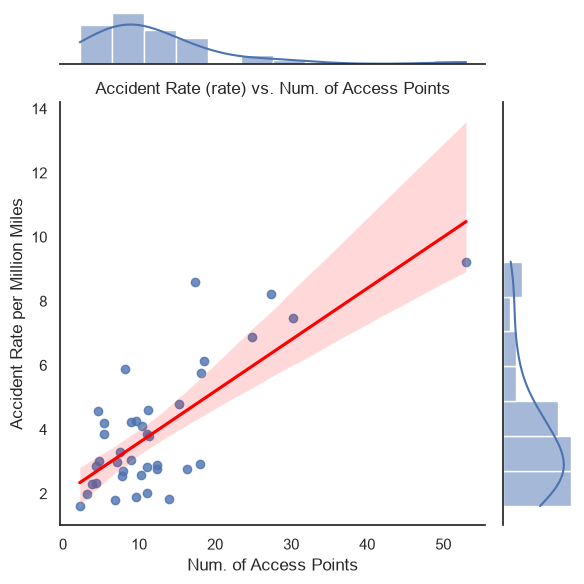

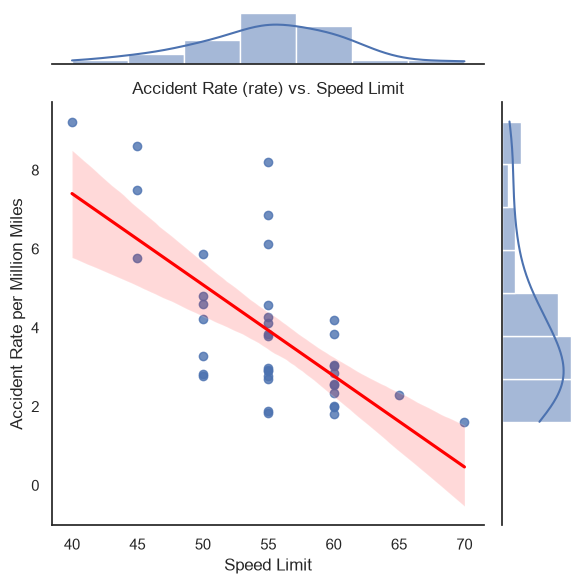

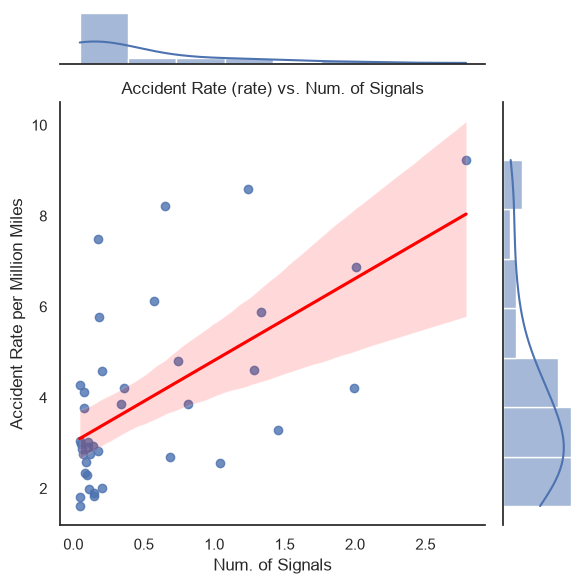

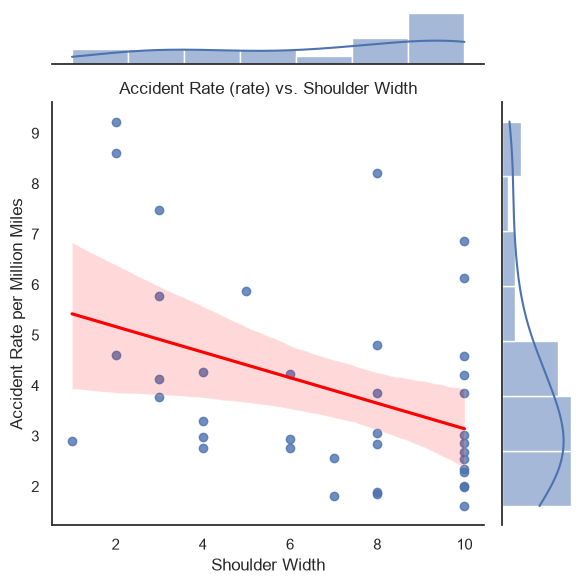

In [17]:
# 绘制带密度分布的散点图
for i in range(0,4):
    sns.set_style('white')
    sns.jointplot(x=design_vars[i], y='rate', data=df, kind='reg', line_kws={'color':'red'})
    plt.title(f'Accident Rate (rate) vs. {labels[i]}')
    plt.xlabel(labels[i])
    plt.ylabel('Accident Rate per Million Miles')
    plt.tight_layout()
    plt.show()

In [18]:
# 哪个变量与事故发生率相关性最高？
corr_matrix['rate'].sort_values(ascending = False)

rate     1.000000
acpt     0.752025
sigs1    0.603191
MA       0.337848
lwid    -0.005619
itg     -0.024841
adt     -0.028570
lane    -0.032979
MC      -0.041311
PA      -0.161540
FAI     -0.207610
shld    -0.386907
len     -0.465290
trks    -0.512522
slim    -0.680984
Name: rate, dtype: float64

#### 回归图：`sns.regplot()`
#### 残差图：`sns.residplot()`

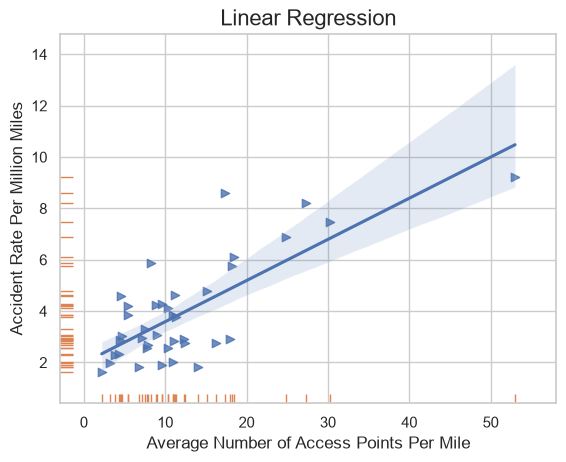

In [19]:
# 绘制事故发生率和每英里汇入点数量(acpt)的线性关系图
sns.set_style('whitegrid')
sns.regplot(data=df, x='acpt', y='rate', marker='>')
sns.rugplot(data=df, x='acpt', y='rate') # 在坐标轴上显示变量的分布，即绘制地毯图
plt.xlabel('Average Number of Access Points Per Mile')
plt.ylabel('Accident Rate Per Million Miles')
plt.title('Linear Regression',fontsize=16)
plt.show()

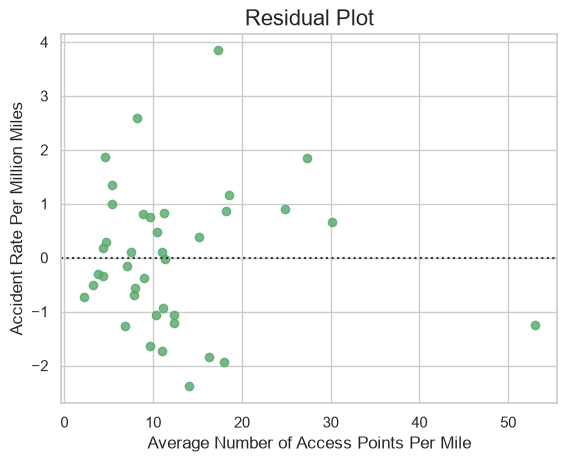

In [20]:
# 绘制线性回归残差图
sns.residplot(data=df, x='acpt', y='rate', color='g')
plt.xlabel('Average Number of Access Points Per Mile')
plt.ylabel('Accident Rate Per Million Miles')
plt.title('Residual Plot',fontsize=16)
plt.show()

### 使用fg-data-profiling生成数据诊断报告

In [21]:
# 导入ProfileReport模块
from data_profiling import ProfileReport

# 读取数据
df = pd.read_csv('Highway1.csv',index_col = 0)

# 创建报告
profile = ProfileReport(df,title='Highway1数据集概览')

# 在Jupyter Notebook中显示
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|████████████████████████████████████████████████████████████████████████████████| 12/12 [00:00<00:00, 2867.08it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [22]:
# 导出为HTML
profile.to_file("report.html")

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### 使用B-vista进行交互式数据诊断与清洗

In [25]:
import bvista
from bvista.server_manager import start_backend
start_backend()

bvista.show(df)